In [11]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

url = "https://books.toscrape.com/"
response = requests.get(url)
response.encoding = "utf-8"   # fixes the £ symbol showing as "Â£"

print("Status code:", response.status_code)   # 200 means success

soup = BeautifulSoup(response.text, "html.parser")

# Map rating words to numbers
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

books = []
for book in soup.find_all("article", class_="product_pod"):
    title = book.h3.a["title"]

    price_text = book.find("p", class_="price_color").text
    price = float(price_text.replace("£", "").strip())

    rating_word = book.find("p", class_="star-rating")["class"][1]
    rating = rating_map[rating_word]

    availability = book.find("p", class_="instock availability").text.strip()

    books.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

df = pd.DataFrame(books)
print(df.shape)
df.head()

Status code: 200
(20, 4)


,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


In [12]:
import time
import requests
import pandas as pd
from bs4 import BeautifulSoup

BASE_URL = "https://books.toscrape.com/catalogue/"
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

def scrape_page(page_number):
    """Scrape one catalogue page and return a list of book dictionaries."""
    url = f"{BASE_URL}page-{page_number}.html"
    response = requests.get(url)
    response.encoding = "utf-8"

    if response.status_code != 200:
        print(f"Page {page_number} failed with status {response.status_code}")
        return []

    soup = BeautifulSoup(response.text, "html.parser")
    page_books = []

    for book in soup.find_all("article", class_="product_pod"):
        title = book.h3.a["title"]
        price = float(book.find("p", class_="price_color").text.replace("£", "").strip())
        rating = rating_map[book.find("p", class_="star-rating")["class"][1]]
        availability = book.find("p", class_="instock availability").text.strip()
        product_url = BASE_URL + book.h3.a["href"]

        page_books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "URL": product_url
        })
    return page_books

# Loop over the pages (change 5 to any number you like)
NUM_PAGES = 5
all_books = []

for page in range(1, NUM_PAGES + 1):
    all_books.extend(scrape_page(page))
    print(f"Scraped page {page}, total books so far: {len(all_books)}")
    time.sleep(0.5)   # be polite to the server

df = pd.DataFrame(all_books)

print(df.shape)
display(df.head())

df.to_csv("competitor_books.csv", index=False)
print("Saved competitor_books.csv")

Scraped page 1, total books so far: 20
Scraped page 2, total books so far: 40
Scraped page 3, total books so far: 60
Scraped page 4, total books so far: 80
Scraped page 5, total books so far: 100
(100, 5)


,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


Saved competitor_books.csv


In [13]:
df.dtypes
df.isnull().sum()

,0
Title,0
Price,0
Rating,0
Availability,0
URL,0


In [14]:
from google.colab import files
files.download("competitor_books.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# Q1. Most expensive book
most_expensive = df.loc[df["Price"].idxmax()]
print("Q1. Most expensive:", most_expensive["Title"], "- £", most_expensive["Price"])

# Q2. Cheapest book
cheapest = df.loc[df["Price"].idxmin()]
print("Q2. Cheapest:", cheapest["Title"], "- £", cheapest["Price"])

# Q3. Average price
print("Q3. Average price: £", round(df["Price"].mean(), 2))

# Q4. Number of 5-star books
five_star_count = (df["Rating"] == 5).sum()
print("Q4. 5-star books:", five_star_count)

# Q5. Percentage in stock
in_stock_pct = (df["Availability"] == "In stock").mean() * 100
print("Q5. In stock: ", round(in_stock_pct, 1), "%")

# Q6. Top 5 highest-rated books (ties broken by lower price)
print("\nQ6. Top 5 highest-rated books:")
top5 = df.sort_values(by=["Rating", "Price"], ascending=[False, True]).head(5)
display(top5[["Title", "Price", "Rating"]])

# Q7. Cheapest 5-star book
five_star = df[df["Rating"] == 5]
cheapest_five = five_star.loc[five_star["Price"].idxmin()]
print("Q7. Cheapest 5-star:", cheapest_five["Title"], "- £", cheapest_five["Price"])

Q1. Most expensive: The Death of Humanity: and the Case for Life - £ 58.11
Q2. Cheapest: Patience - £ 10.16
Q3. Average price: £ 34.56
Q4. 5-star books: 19
Q5. In stock:  100.0 %

Q6. Top 5 highest-rated books:


,Title,Price,Rating
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5
34,Sophie's World,15.94,5
54,Thirst,17.27,5
12,Set Me Free,17.46,5


Q7. Cheapest 5-star: Princess Between Worlds (Wide-Awake Princess #5) - £ 13.34


Rating
1    22
2    19
3    22
4    18
5    19
Name: count, dtype: int64


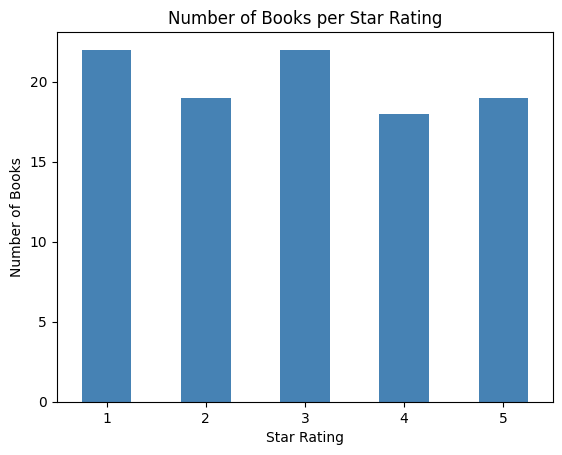

In [16]:
import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar", color="steelblue")
plt.title("Number of Books per Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.show()

In [17]:
# --- CEO £100 Challenge ---
BUDGET = 100.0

# Work on a copy, keep only in-stock books
pool = df[df["Availability"] == "In stock"].copy()

# Best value first: most stars per pound
pool["Value"] = pool["Rating"] / pool["Price"]
pool = pool.sort_values(by="Value", ascending=False)

selected = []
total_cost = 0.0

for _, row in pool.iterrows():
    if total_cost + row["Price"] <= BUDGET:
        selected.append(row)
        total_cost += row["Price"]

chosen = pd.DataFrame(selected)[["Title", "Price", "Rating"]]

print("Selected books:")
display(chosen)
print("Number of books :", len(chosen))
print("Total cost      : £", round(chosen["Price"].sum(), 2))
print("Total rating    :", chosen["Rating"].sum())
print("Money left      : £", round(BUDGET - chosen["Price"].sum(), 2))

Selected books:


,Title,Price,Rating
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5
34,Sophie's World,15.94,5
84,Patience,10.16,3
54,Thirst,17.27,5
12,Set Me Free,17.46,5


Number of books : 6
Total cost      : £ 87.78
Total rating    : 28
Money left      : £ 12.22


In [18]:
avg_price = df["Price"].mean()
target = df[(df["Rating"] >= 4) & (df["Price"] < avg_price) & (df["Availability"] == "In stock")]
print("Average price: £", round(avg_price, 2))
print("4-5 star, below-average-price, in-stock books:", len(target))
display(target.sort_values(by=["Rating", "Price"], ascending=[False, True]).head(10)[["Title", "Price", "Rating"]])

Average price: £ 34.56
4-5 star, below-average-price, in-stock books: 21


,Title,Price,Rating
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5
34,Sophie's World,15.94,5
54,Thirst,17.27,5
12,Set Me Free,17.46,5
30,The Four Agreements: A Practical Guide to Pers...,17.66,5
65,The Inefficiency Assassin: Time Management Tac...,20.59,5
43,#HigherSelfie: Wake Up Your Life. Free Your So...,23.11,5
32,The Elephant Tree,23.82,5
23,Chase Me (Paris Nights #2),25.27,5


In [19]:
BUDGET = 100.0

# Keep only in-stock books
pool = df[df["Availability"] == "In stock"].copy()

# Best value first: most stars per pound
pool["Value"] = pool["Rating"] / pool["Price"]
pool = pool.sort_values(by="Value", ascending=False)

selected = []
total_cost = 0.0

for _, row in pool.iterrows():
    if total_cost + row["Price"] <= BUDGET:
        selected.append(row)
        total_cost += row["Price"]

chosen = pd.DataFrame(selected)[["Title", "Price", "Rating"]]

print("Selected books:")
display(chosen)
print("Number of books :", len(chosen))
print("Total cost      : £", round(chosen["Price"].sum(), 2))
print("Total rating    :", chosen["Rating"].sum())
print("Money left      : £", round(BUDGET - chosen["Price"].sum(), 2))

Selected books:


,Title,Price,Rating
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5
34,Sophie's World,15.94,5
84,Patience,10.16,3
54,Thirst,17.27,5
12,Set Me Free,17.46,5


Number of books : 6
Total cost      : £ 87.78
Total rating    : 28
Money left      : £ 12.22
